# Cyber Incidents in Germany – Exploratory Data Analysis & Harmonization Pipeline

## 1. Research Purpose & Methodological Framework (Course: Modeli in Odločitveni Sistemi)

As student researchers in decision models, our goal is to investigate cyber incidents targeting German organizations and develop a data-driven foundation for national cybersecurity resource allocation. When working with real-world cybersecurity data, we quickly encounter a fundamental challenge: **no single dataset records all cyberattacks**, and different organizations collect data with different definitions, scopes, and timeframes.

### 1.1 The Critical Need for Incident Enrichment (Moving Beyond Simple Counts)
In traditional descriptive analyses, researchers often stop at counting incidents by sector or country. However, from the perspective of **Decision Analysis (Podatkovno podprto odločanje)**, counting incidents alone is fundamentally insufficient:
$$\text{Risk} = \text{Likelihood (Frequency)} \times \text{Severity (Impact)}$$

To determine **which sectors and threats require maximum preventive budget and mitigation resources** (Simon's problem-solving cycle: *Intelligence $\to$ Design $\to$ Choice $\to$ Reflection*), a decision-maker must evaluate multi-dimensional consequences:
1. **Operational Disruption (Availability)**: Did the attack halt critical operations, hospital admissions, or municipal services (`has_disruption`, `functional_impact`)?
2. **Confidentiality & Data Exfiltration (Integrity / Confidentiality)**: Was sensitive citizen PII, financial data, or intellectual property stolen (`has_data_theft`, `data_breach_scope`)?
3. **Quantitative Attack Severity**: How intense was the incident on an objective scale (`severity_intensity_score`)?
4. **Initial Attack Vector (MITRE ATT&CK)**: Did the attack enter through employee human error (`requires_user_interaction`, e.g. phishing) or unpatched internet-facing servers (`initial_access_vector`, `zero_day_indicator`)? This dictates whether funding should prioritize *employee security awareness training* or *vulnerability patching / EDR automation*.

### 1.2 Pipeline Objectives
This notebook implements an end-to-end exploratory and harmonization pipeline:
1. **Inspect raw sources**: Explore fields, categories, and severity metrics across international and national trackers.
2. **Diagnose structural & ontological gaps**: Map how UMD, EuRepoC, and KonBriefing differently classify sectors, attack vectors, and impacts.
3. **Harmonize & Enrich**: Standardize sectors into 10 unified classes, isolate ransomware families, and extract operational downtime, data breach scopes, and MITRE initial access vectors.
4. **Fuzzy Deduplication**: Identify and merge overlapping multi-source reporting of incidents using a $\pm 14$-day window and string similarity matching.
5. **Produce Two Enriched, Analysis-Ready Datasets**:
   - **`germany_large_incidents.csv`**: 1,209 deduplicated German incidents with 23 standardized dimensions covering victim profile, threat actor, attack mechanics, and operational/data consequences.
   - **`germany_yearly_overview.csv`**: 2014–2026 macro time series combining World Bank indicators, BKA police mass cybercrime, Bitkom damages, Eurostat base-rates, and annual large incident disruption dynamics.

---

## 2. Overview of Data Sources

| Dataset | File in `raw/` | Source & Link | Scope & Collection Mechanism |
| :--- | :--- | :--- | :--- |
| **UMD CISSM Cyber Events Database** | `umd_cyber_events.xlsx` | [UMD GoTech Lab](https://gotech.umd.edu/cyber-events-database) | Global academic OSINT database. Strong on motive and actor type; records magnitude, duration, and compromised data types. |
| **EuRepoC v1.3** | `eurepoc_global.csv`, `eurepoc_receiver.csv`, `eurepoc_attribution.csv` | [EuRepoC Repository](https://eurepoc.eu/) / [Zenodo](https://doi.org/10.5281/zenodo.14965395) | European academic tracker (Heidelberg, SWP, Sciences Po). 85 variables including scientific intensity scores, functional downtime, MITRE tactics, and state attribution. |
| **KonBriefing Germany Archive** | `konbriefing_germany.csv` | [KonBriefing Research](https://konbriefing.com/en-topics/hacker-attacks-germany.html) | German-native cybersecurity news monitor (`2021–2026`). Tracks German municipal, hospital, university, and *Mittelstand* corporate attacks missed by English trackers. |
| **World Bank WDI** | `world_bank_germany.csv` | [World Bank Germany](https://data.worldbank.org/country/germany) | Official annual economic and digital infrastructure indicators (`GDP`, `broadband`, `internet users %`, `R&D % of GDP`). |
| **BKA, Bitkom & Eurostat** | `bka_bitkom_eurostat_yearly.csv` | [BKA Cybercrime](https://www.bka.de/) · [Bitkom](https://www.bitkom.org/) · [Eurostat](https://ec.europa.eu/eurostat/) | Official German police cybercrime counts (*Inlandstaten* & *Auslandstaten*), corporate damage estimates in € billions, and EU enterprise survey percentages. |


In [1]:
# Standard scientific Python stack for data analysis and visualization
from pathlib import Path
from difflib import SequenceMatcher
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Configure notebook visualization styling for clear academic presentation
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.dpi"] = 120

# Define project directories
BASE_DIR = Path(".").resolve()
RAW_DIR = BASE_DIR / "raw"

print(f"Working directory: {BASE_DIR}")
print(f"Raw data directory: {RAW_DIR}")
assert RAW_DIR.is_dir(), f"Raw directory missing: {RAW_DIR}"



Working directory: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany
Raw data directory: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\raw


---

## 3. Loading the Raw Incident Sources and Initial Inspection

Let us load each of the three incident datasets, isolate the records concerning **Germany**, and inspect their general shapes.


In [2]:
# 1. Load UMD CISSM
umd_global = pd.read_excel(RAW_DIR / "umd_cyber_events.xlsx")
umd_de = umd_global[
    (umd_global["country"] == "Germany") | (umd_global["country_iso3"] == "DEU")
].copy()

# 2. Load EuRepoC tables and isolate German receivers
eurepoc_global = pd.read_csv(RAW_DIR / "eurepoc_global.csv", low_memory=False)
eurepoc_receiver = pd.read_csv(RAW_DIR / "eurepoc_receiver.csv", low_memory=False)
eurepoc_attr = pd.read_csv(RAW_DIR / "eurepoc_attribution.csv", low_memory=False)

# Identify incidents where Germany was the target (receiver)
de_receivers = eurepoc_receiver[
    eurepoc_receiver["country"].astype(str).str.contains("Germany", case=False, na=False)
].copy()

def join_unique(series, skip_tokens=("Not available", "Unknown", "Not attributed", "nan")):
    vals = [str(v).strip() for v in series.dropna() if str(v).strip() and str(v).strip() not in skip_tokens]
    res = []
    for x in vals:
        if x not in res:
            res.append(x)
    return "; ".join(res) if res else "Unknown"

# Aggregate multiple receivers and attributions per incident_id
de_rec_summary = (
    de_receivers.groupby("incident_id", as_index=False)
    .agg(
        de_victim_name=("name", join_unique),
        de_category=("category", join_unique),
        de_subcategory=("subcategory", join_unique),
    )
)

de_attr_summary = (
    eurepoc_attr[eurepoc_attr["incident_id"].isin(de_rec_summary["incident_id"])]
    .groupby("incident_id", as_index=False)
    .agg(
        attr_actor_name=("initiator_name", join_unique),
        attr_country=("initiator_country", join_unique),
        attr_category=("initiator_category", join_unique),
    )
)

# Merge back with the full 85-column EuRepoC global incident table
eurepoc_de = (
    eurepoc_global[eurepoc_global["incident_id"].isin(de_rec_summary["incident_id"])]
    .merge(de_rec_summary, on="incident_id", how="left")
    .merge(de_attr_summary, on="incident_id", how="left")
)

# 3. Load KonBriefing Germany
kb_raw = pd.read_csv(RAW_DIR / "konbriefing_germany.csv")

print(f"UMD Germany incidents:       {len(umd_de):>4} rows (out of {len(umd_global):,} global)")
print(f"EuRepoC Germany incidents:   {len(eurepoc_de):>4} rows (out of {len(eurepoc_global):,} global)")
print(f"KonBriefing Germany records: {len(kb_raw):>4} rows")



UMD Germany incidents:        291 rows (out of 17,016 global)
EuRepoC Germany incidents:    168 rows (out of 3,414 global)
KonBriefing Germany records:  860 rows


### 3.1 Initial Comparison: Volume and Time Coverage
How do these three datasets compare in terms of historical coverage? Let us plot the raw yearly counts before modifying any columns.


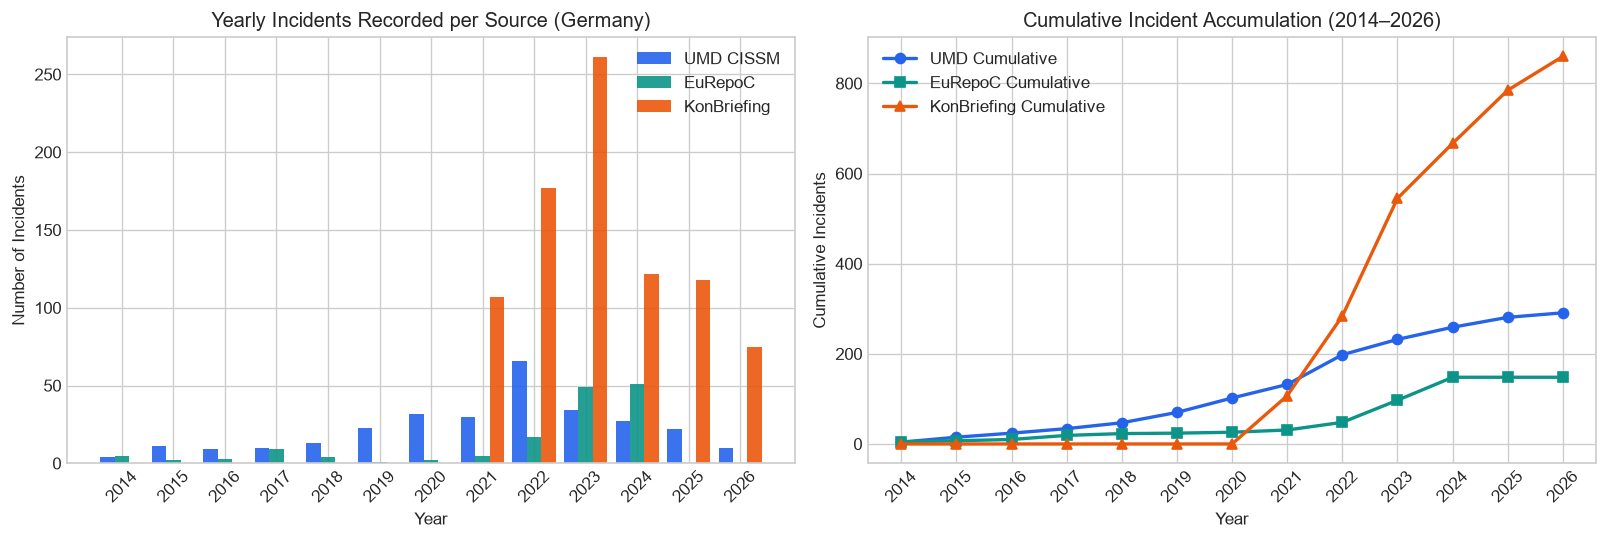

In [3]:
umd_years = pd.to_datetime(umd_de["event_date"], errors="coerce").dt.year
eur_years = pd.to_datetime(eurepoc_de["start_date"], dayfirst=True, format="mixed", errors="coerce").dt.year
kb_years = pd.to_datetime(
    kb_raw["date_raw"].astype(str).str.replace("?", "", regex=False).str.strip(),
    format="mixed", errors="coerce"
).dt.year

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Left: Yearly counts per dataset (2014-2026)
years = np.arange(2014, 2027)
w = 0.28
u_counts = [int((umd_years == y).sum()) for y in years]
e_counts = [int((eur_years == y).sum()) for y in years]
k_counts = [int((kb_years == y).sum()) for y in years]

axes[0].bar(years - w, u_counts, width=w, label="UMD CISSM", color="#2563eb", alpha=0.9)
axes[0].bar(years, e_counts, width=w, label="EuRepoC", color="#0d9488", alpha=0.9)
axes[0].bar(years + w, k_counts, width=w, label="KonBriefing", color="#ea580c", alpha=0.9)
axes[0].set_title("Yearly Incidents Recorded per Source (Germany)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Incidents")
axes[0].set_xticks(years)
axes[0].set_xticklabels([str(y) for y in years], rotation=45)
axes[0].legend()

# Right: Cumulative historical volume
axes[1].plot(years, np.cumsum(u_counts), marker="o", label="UMD Cumulative", color="#2563eb", linewidth=2)
axes[1].plot(years, np.cumsum(e_counts), marker="s", label="EuRepoC Cumulative", color="#0d9488", linewidth=2)
axes[1].plot(years, np.cumsum(k_counts), marker="^", label="KonBriefing Cumulative", color="#ea580c", linewidth=2)
axes[1].set_title("Cumulative Incident Accumulation (2014–2026)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Cumulative Incidents")
axes[1].set_xticks(years)
axes[1].set_xticklabels([str(y) for y in years], rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()



**Observation from our initial timeline:**
- **UMD** and **EuRepoC** give us a steady baseline of 10 to 35 incidents per year starting from 2014.
- In **2021–2026**, **KonBriefing** brings a massive surge of over 100–300 additional German records per year.
- **Student Question:** *Why did incident counts jump so much after 2021?* Is it because cyberattacks suddenly quadrupled, or because KonBriefing captures local German media (like municipal halls and regional clinics) that international trackers ignore?
To answer this, we need to explore **what sectors, attack types, and consequence dimensions are actually recorded inside each dataset**.

---

## 4. Step-by-Step Exploration: Understanding Raw Variables & Consequence Fields

Before writing harmonization code, a researcher must inspect the raw values across each source.

### 4.1 Step 1: Investigating Raw Target Sectors
Which columns in each dataset indicate who was targeted, and what values do they hold?
- In **UMD**, sector is in `industry`.
- In **EuRepoC**, target information is in `de_category` and `de_subcategory`.
- In **KonBriefing**, target information is in `victim_type` and `keywords`.


C:\Users\Nitro\AppData\Local\Temp\ipykernel_26372\2043219215.py:24: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


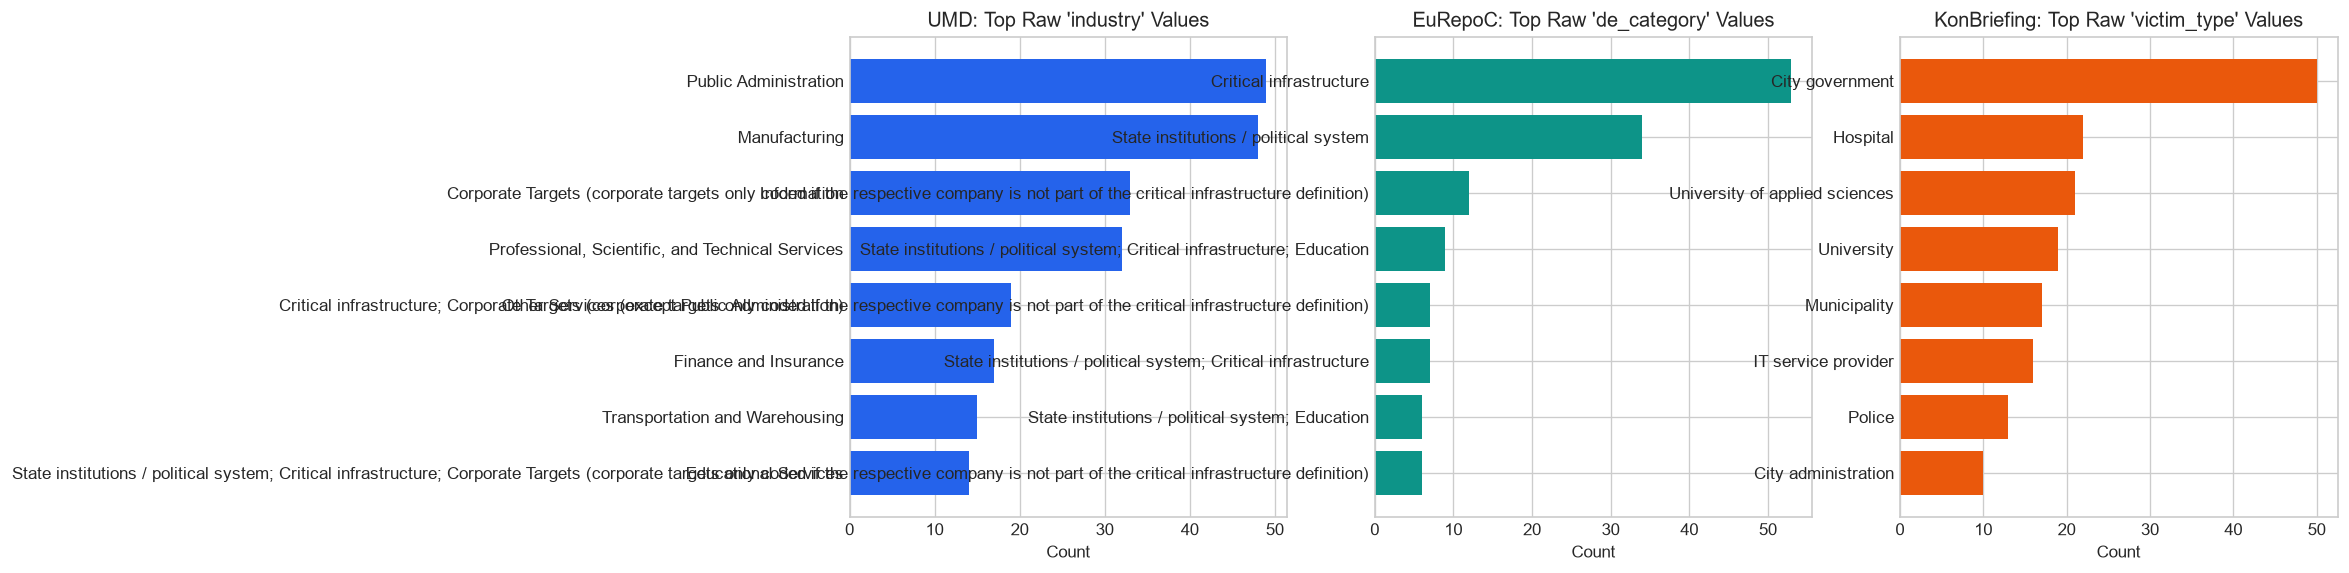

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

# 1. UMD raw industries
umd_top_ind = umd_de["industry"].fillna("Missing").value_counts().head(8)
axes[0].barh(umd_top_ind.index, umd_top_ind.values, color="#2563eb")
axes[0].invert_yaxis()
axes[0].set_title("UMD: Top Raw 'industry' Values")
axes[0].set_xlabel("Count")

# 2. EuRepoC raw categories
eur_top_cat = eurepoc_de["de_category"].fillna("Missing").value_counts().head(8)
axes[1].barh(eur_top_cat.index, eur_top_cat.values, color="#0d9488")
axes[1].invert_yaxis()
axes[1].set_title("EuRepoC: Top Raw 'de_category' Values")
axes[1].set_xlabel("Count")

# 3. KonBriefing raw victim types
kb_top_vt = kb_raw["victim_type"].fillna("Missing").value_counts().head(8)
axes[2].barh(kb_top_vt.index, kb_top_vt.values, color="#ea580c")
axes[2].invert_yaxis()
axes[2].set_title("KonBriefing: Top Raw 'victim_type' Values")
axes[2].set_xlabel("Count")

plt.tight_layout()
plt.show()



**What the sector exploration reveals:**
- **Different naming conventions**:
  - UMD uses NAICS-style categories: `"Public Administration"`, `"Manufacturing"`, `"Information"`.
  - EuRepoC uses security-focused classifications: `"Civil service / administration"`, `"Health"`, `"Energy"`, `"Critical Manufacturing"`.
  - KonBriefing uses German-translated public entities: `"Municipality"`, `"Company"`, `"Hospital"`, `"Church / religion"`.
- **Target mapping blueprint**: All three can be cleanly harmonized into **10 unified sectors**:
  1. *Public Administration & Government*
  2. *Healthcare*
  3. *Education & Research*
  4. *Manufacturing & Industry*
  5. *Energy & Utilities*
  6. *IT & Telecommunications*
  7. *Finance & Insurance*
  8. *Transportation & Logistics*
  9. *Retail, Trade & Services*
  10. *Media, NGOs & Other*

---

### 4.2 Step 2: Investigating Raw Attack Types & Threat Actors
How do the datasets describe what happened and who did it?


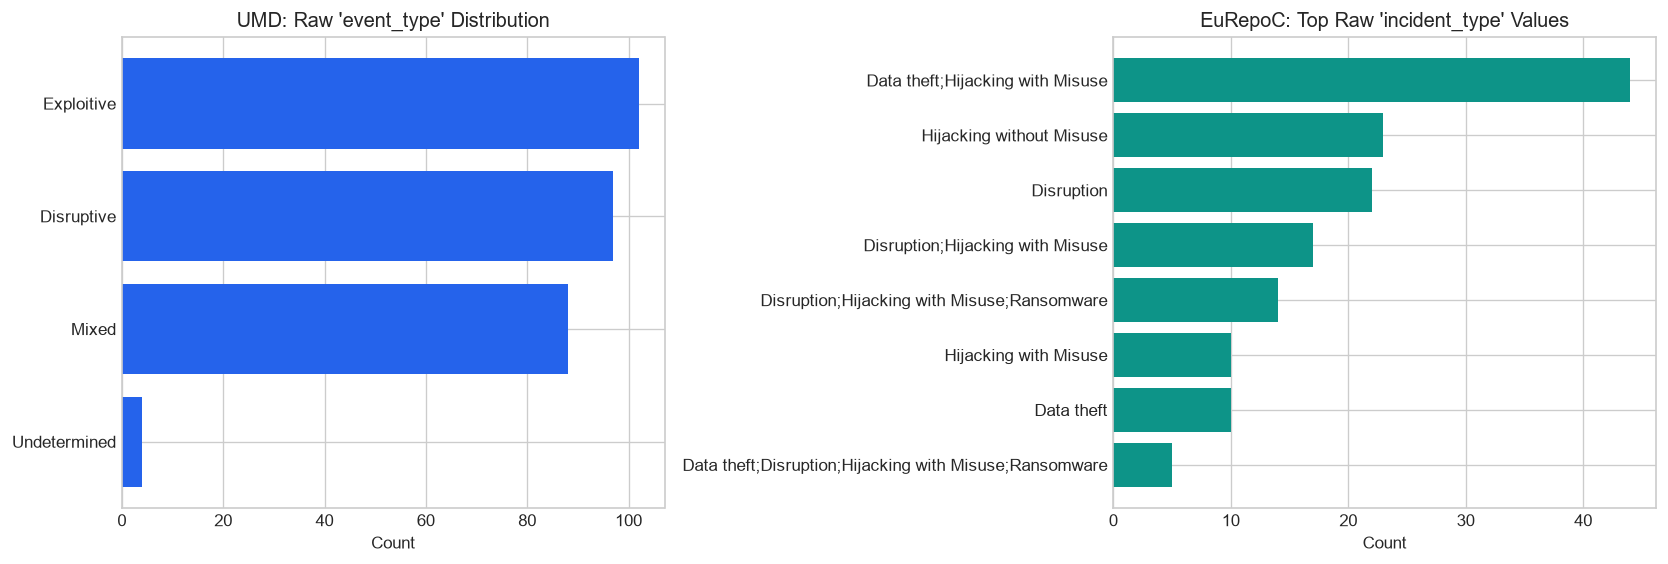

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. UMD raw event_type
umd_et = umd_de["event_type"].fillna("Missing").value_counts()
axes[0].barh(umd_et.index, umd_et.values, color="#2563eb")
axes[0].invert_yaxis()
axes[0].set_title("UMD: Raw 'event_type' Distribution")
axes[0].set_xlabel("Count")

# 2. EuRepoC raw incident_type
eur_it = eurepoc_de["incident_type"].fillna("Missing").value_counts().head(8)
axes[1].barh(eur_it.index, eur_it.values, color="#0d9488")
axes[1].invert_yaxis()
axes[1].set_title("EuRepoC: Top Raw 'incident_type' Values")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()



**Key discovery regarding attack types and severity:**
- **UMD lacks a dedicated `"Ransomware"` tag in `event_type`!** Instead, UMD codes ransomware incidents under high-level categories like `"Exploitive"` or `"Disruptive"`, and mentions the ransomware family (e.g. LockBit, BlackBasta) in the free-text `description`.
- **EuRepoC provides rigorous consequence and severity variables**:
  - `weighted_intensity` (0 to 4 scale, based on systemic disruption and target importance)
  - `functional_impact` (duration of downtime: Days, Weeks, No disruption)
  - `mitre_initial_access` (MITRE ATT&CK initial entry vectors: Phishing, Public Exploit, Valid Accounts)
  - `economic_impact_value` (estimated financial losses in €)
- **UMD provides impact and breach scope**:
  - `magnitude` and `duration` (operational impact)
  - `cust_data`, `org_data`, and `ip` (confidentiality scope: customer PII vs trade secrets)
- **KonBriefing records keywords**:
  - Contains German tags identifying double-extortion ransomware, DDoS, and website outages.

Let us explore these raw consequence and severity variables across UMD and EuRepoC.


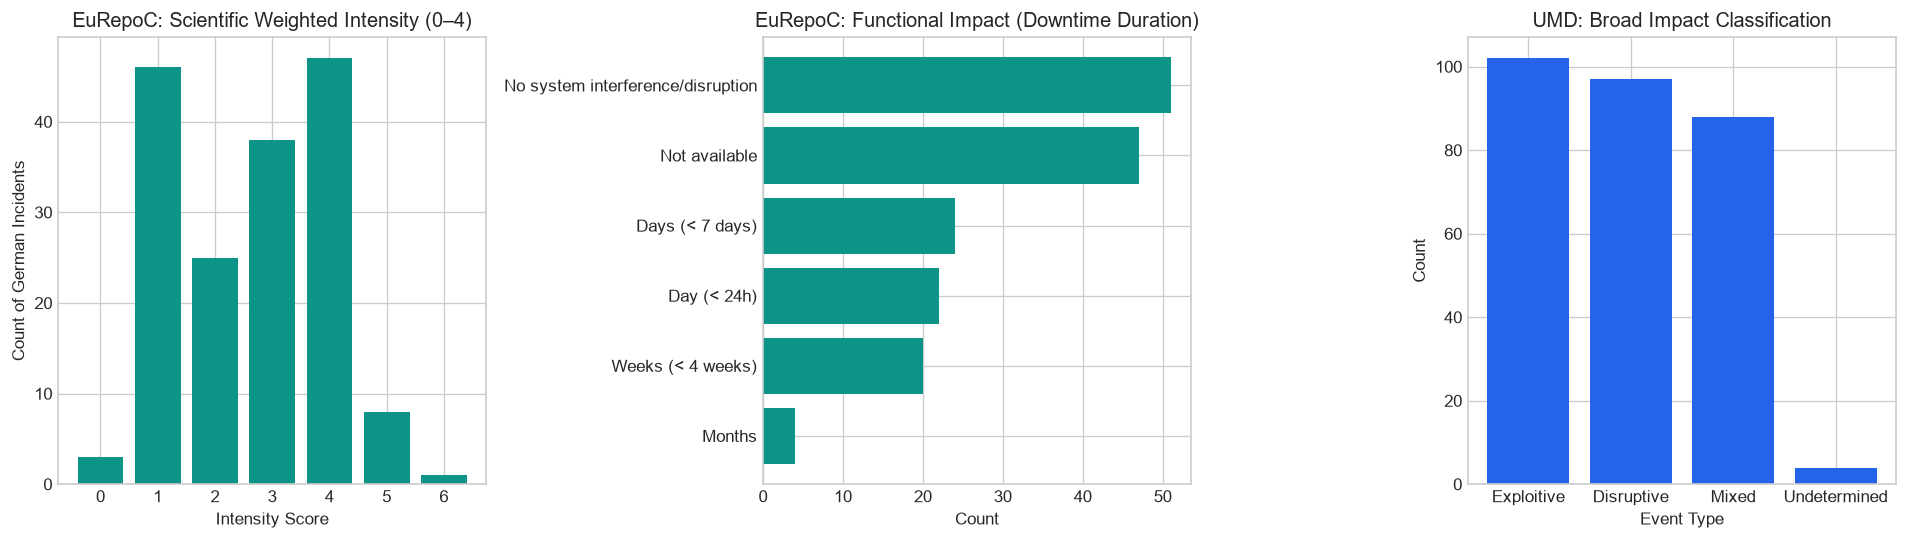

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# 1. EuRepoC Weighted Intensity Score
eur_int = eurepoc_de["weighted_intensity"].dropna().value_counts().sort_index()
axes[0].bar([str(int(k)) for k in eur_int.index], eur_int.values, color="#0d9488")
axes[0].set_title("EuRepoC: Scientific Weighted Intensity (0–4)")
axes[0].set_xlabel("Intensity Score")
axes[0].set_ylabel("Count of German Incidents")

# 2. EuRepoC Functional Impact (Downtime Duration)
eur_func = eurepoc_de["functional_impact"].dropna().value_counts()
axes[1].barh(eur_func.index, eur_func.values, color="#0d9488")
axes[1].invert_yaxis()
axes[1].set_title("EuRepoC: Functional Impact (Downtime Duration)")
axes[1].set_xlabel("Count")

# 3. UMD Broad Impact Classification (Disruptive vs Exploitive)
umd_broad = umd_de["event_type"].dropna().value_counts()
axes[2].bar(umd_broad.index, umd_broad.values, color="#2563eb")
axes[2].set_title("UMD: Broad Impact Classification")
axes[2].set_xlabel("Event Type")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()



**Observation on Attacker Attribution & Consequence Mapping:**
- UMD codes Russia as `"Russian Federation"`, while EuRepoC codes it as `"Russia"`. Similarly, North Korea appears with slight variations.
- To serve our **Decision-Making Model (Modeli in odločitveni sistemi)**, our harmonization pipeline will not just extract categories, but **enrich every incident with standardized risk dimensions**:
  1. `has_disruption` (Boolean: whether operational systems/services went down).
  2. `has_data_theft` (Boolean: whether confidential records were exfiltrated).
  3. `functional_impact` (Harmonized downtime: `None`, `Hours (< 24h)`, `Days (< 7d)`, `Weeks+`, `Unknown`).
  4. `data_breach_scope` (Type of compromise: `Customer PII`, `Internal Data`, `Intellectual Property`, `None`).
  5. `severity_intensity_score` (Quantitative 1–5 scale matching EuRepoC intensity).
  6. `initial_access_vector` (MITRE ATT&CK taxonomy: Phishing, Public Exploit, Stolen Credentials).
  7. `requires_user_interaction` (Boolean: whether employee human error was exploited).

---

## 5. Designing the Harmonization & Enrichment Functions

We now implement robust, granularly commented cleaning and mapping functions.


In [7]:
def fix_mojibake(text):
    # Repair double-encoded UTF-8 German characters (e.g. 'Ã¤' -> 'ä')
    # caused by legacy Windows Latin-1 CSV decoding.
    if pd.isna(text):
        return ""
    s = str(text).strip()
    if "Ã" in s:
        try:
            s = s.encode("latin1").decode("utf-8")
        except UnicodeError:
            pass
    return re.sub(r"\s+", " ", s)


def clean_country_name(raw_country):
    # Unify country naming variations across international trackers
    s = fix_mojibake(raw_country)
    replacements = {
        "Russian Federation": "Russia",
        "Korea, Democratic People's Republic of": "North Korea",
        "Korea (the Democratic People's Republic of)": "North Korea",
        "Iran, Islamic Republic of": "Iran",
        "Iran (Islamic Republic of)": "Iran",
        "Viet Nam": "Vietnam",
        ", Not available": "",
    }
    for old, new in replacements.items():
        s = s.replace(old, new)
    s = s.strip()
    return s if s and s not in {"Not attributed", "Not available", "Undetermined", "Unknown"} else "Unknown"


def standardize_sector(raw_text):
    # Map observed industry, receiver, and keyword strings into 10 target sectors
    t = fix_mojibake(raw_text).lower()
    if not t or t in {"unknown", "undetermined", "not available", "nan"}:
        return "Unknown"

    if any(k in t for k in ["public administration", "government", "ministry", "ministries", "municipality",
                            "city ", "county", "state institution", "civil service", "police", "parliament",
                            "authority", "federal", "administration", "defence", "military", "court", "embassy"]):
        return "Public Administration & Government"
    if any(k in t for k in ["health", "hospital", "clinic", "medical", "klinik", "pharma", "care", "welfare", "red cross"]):
        return "Healthcare"
    if any(k in t for k in ["education", "university", "school", "science", "research", "hochschule", "institute"]):
        return "Education & Research"
    if any(k in t for k in ["manufactur", "automotive", "industrial", "machinery", "metal", "chemical",
                            "electronics", "aerospace", "engineering", "factory", "producer", "supplier"]):
        return "Manufacturing & Industry"
    if any(k in t for k in ["utilit", "energy", "electric", "power", "water", "gas", "wind", "solar", "stadtwerke", "disposal"]):
        return "Energy & Utilities"
    if any(k in t for k in ["information", "telecom", "it service", "software", "cloud", "hosting", "digital", "internet", "tech"]):
        return "IT & Telecommunications"
    if any(k in t for k in ["finance", "bank", "insurance", "sparkasse", "volksbank", "financial", "credit", "investment"]):
        return "Finance & Insurance"
    if any(k in t for k in ["transport", "warehous", "logistics", "airline", "aviation", "airport", "railway", "transit", "shipping", "port"]):
        return "Transportation & Logistics"
    if any(k in t for k in ["retail", "wholesale", "store", "shop", "commerce", "hotel", "accommodation", "food",
                            "real estate", "construction", "law firm", "legal", "consulting", "professional", "chamber"]):
        return "Retail, Trade & Services"
    if any(k in t for k in ["media", "newspaper", "publishing", "broadcast", "museum", "church", "religion",
                            "association", "union", "party", "social", "sport", "other services"]):
        return "Media, NGOs & Other"
    return "Media, NGOs & Other"


def standardize_attack_type(raw_type, description=""):
    # Identify attack method using type strings and description keywords,
    # solving UMD's lack of a dedicated 'Ransomware' category.
    combined = f"{fix_mojibake(raw_type)} {fix_mojibake(description)}".lower()
    if not combined.strip() or combined.strip() in {"unknown", "undetermined", "not available"}:
        return "Unknown"

    if any(k in combined for k in ["ransomware", "encrypted the", "encrypting", "lockbit", "blackbasta", "akira", "conti", "ryuk", "qilin"]):
        return "Ransomware"
    if any(k in combined for k in ["denial of service", "ddos", "dos attack", "website unavailable", "websites' accessibility"]):
        return "DDoS / Disruption"
    if any(k in combined for k in ["phishing", "credential", "voice clone", "deepfake", "ceo fraud", "social engineering", "message manipulation"]):
        return "Phishing / Social Engineering"
    if any(k in combined for k in ["data theft", "data attack", "data breach", "exfiltrat", "stole data", "stolen data", "leaked"]):
        return "Data Breach / Data Theft"
    if any(k in combined for k in ["hijacking", "exploitation", "intrusion", "espionage", "unauthorized access", "gained access", "malware", "wiper"]):
        return "System Intrusion / Malware"
    if "disrupt" in combined:
        return "DDoS / Disruption"
    return "Unknown"


def standardize_actor_type(raw_actor):
    # Group threat actor classifications into Criminal, State-Sponsored, Hacktivist
    t = fix_mojibake(raw_actor).lower()
    if not t or any(k in t for k in ["undetermined", "unknown", "not attributed", "not available"]):
        return "Unknown"
    if any(k in t for k in ["nation-state", "state", "apt"]):
        return "State-Sponsored"
    if "criminal" in t:
        return "Criminal"
    if "hacktivist" in t:
        return "Hacktivist"
    return "Other"


def standardize_motive(raw_motive, actor_type="Unknown", attack_type="Unknown"):
    # Harmonize motive labels across sources
    t = fix_mojibake(raw_motive).lower()
    if "financial" in t:
        return "Financial"
    if "espionage" in t:
        return "Espionage"
    if "protest" in t or "hacktiv" in t:
        return "Hacktivism / Protest"
    if "sabotage" in t:
        return "Sabotage / Disruption"
    if actor_type == "Criminal" or attack_type == "Ransomware":
        return "Financial"
    if actor_type == "Hacktivist":
        return "Hacktivism / Protest"
    if actor_type == "State-Sponsored":
        return "Sabotage / Disruption" if attack_type == "DDoS / Disruption" else "Espionage"
    return "Unknown"


# ==========================================
# NEW ENRICHMENT FUNCTIONS FOR DECISION SUPPORT
# ==========================================

def standardize_functional_impact(raw_impact_text):
    # Maps operational downtime into standard duration categories:
    # 'None', 'Hours (< 24h)', 'Days (< 7d)', 'Weeks+', 'Unknown'
    t = fix_mojibake(raw_impact_text).lower()
    if not t or any(k in t for k in ["unknown", "undetermined", "not available", "nan", "indeterminate"]):
        return "Unknown"
    if any(k in t for k in ["week", "month", "extended", "complete loss"]):
        return "Weeks+"
    if any(k in t for k in ["day", "several days", "days (< 7 days)"]):
        return "Days (< 7d)"
    if any(k in t for k in ["hour", "day (< 24h)", "short-term", "24h"]):
        return "Hours (< 24h)"
    if any(k in t for k in ["no system", "none", "no disruption"]):
        return "None"
    return "Unknown"


def standardize_initial_access(vector_raw, desc=""):
    # Categorize initial entry vector according to MITRE ATT&CK taxonomy
    combined = f"{fix_mojibake(vector_raw)} {fix_mojibake(desc)}".lower()
    if any(k in combined for k in ["phish", "spearphish", "social engineering", "malicious email", "attachment", "message manipulation"]):
        return "Phishing / Social Engineering"
    if any(k in combined for k in ["exploit public", "application server", "web application", "vpn exploit", "remote code execution", "log4j", "cve-"]):
        return "Exploit Public-Facing Application"
    if any(k in combined for k in ["valid account", "stolen credential", "brute force", "credential stuffing", "password", "vpn access"]):
        return "Valid Accounts / Stolen Credentials"
    if any(k in combined for k in ["supply chain", "third-party", "vendor", "software update", "it provider"]):
        return "Supply Chain / Third-Party"
    if any(k in combined for k in ["physical attack", "hardware"]):
        return "Physical / Hardware"
    if any(k in combined for k in ["ransomware", "encrypt"]):
        return "System Intrusion / Ransomware Vector"
    return "Unknown / Undetermined"



### 5.1 Applying Harmonization and Enrichment to Each Dataset
We now apply these functions to create three standardized DataFrames with an identical 20-column schema.


In [8]:
# 1. Standardize UMD
umd_clean = pd.DataFrame()
umd_clean["date"] = pd.to_datetime(umd_de["event_date"], errors="coerce")
umd_clean["victim_name"] = umd_de["organization"].fillna("Unknown").apply(fix_mojibake)
umd_clean["location_detail"] = umd_de["state"].fillna("Unknown").apply(fix_mojibake)
umd_clean["sector"] = [standardize_sector(f"{ind} {org}") for ind, org in zip(umd_de["industry"], umd_de["organization"])]
umd_clean["attack_type"] = [standardize_attack_type(f"{et} {es}", desc) for et, es, desc in zip(umd_de["event_type"], umd_de["event_subtype"], umd_de["description"])]
umd_clean["actor_type"] = umd_de["actor_type"].apply(standardize_actor_type)
umd_clean["actor_name"] = umd_de["actor"].fillna("Unknown").replace({"Undetermined": "Unknown"}).apply(fix_mojibake)
umd_clean["initiator_country"] = umd_de["actor_country"].apply(clean_country_name)
umd_clean["motive"] = [standardize_motive(mot, act_t, att_t) for mot, act_t, att_t in zip(umd_de["motive"], umd_clean["actor_type"], umd_clean["attack_type"])]

# Enriched Consequence & Technical Vector Variables for UMD
umd_desc_lower = umd_de["description"].fillna("").astype(str).str.lower()
umd_clean["has_disruption"] = (
    umd_de["event_type"].isin(["Disruptive", "Mixed"]) |
    umd_de["event_subtype"].astype(str).str.contains("Denial of Service", case=False, na=False) |
    umd_desc_lower.str.contains("disrupt|encrypt|shutdown|offline|unavailable|paralyz|halt", regex=True)
)
umd_clean["has_data_theft"] = (
    umd_de["event_type"].isin(["Exploitive", "Mixed"]) |
    (umd_de["org_data"].notna() & ~umd_de["org_data"].astype(str).str.contains("None reported", case=False, na=False)) |
    (umd_de["cust_data"].notna() & ~umd_de["cust_data"].astype(str).str.contains("None reported", case=False, na=False)) |
    (umd_de["ip"].notna() & ~umd_de["ip"].astype(str).str.contains("None reported", case=False, na=False)) |
    umd_desc_lower.str.contains("exfiltrat|stolen|stole|breach|leak|dumped", regex=True)
)
umd_clean["functional_impact"] = [standardize_functional_impact(f"{dur} {mag}") for dur, mag in zip(umd_de["duration"], umd_de["magnitude"])]

def get_umd_data_scope(ip, cust, org, theft):
    if pd.notna(ip) and "none reported" not in str(ip).lower():
        return "Intellectual Property / Trade Secrets"
    if pd.notna(cust) and "none reported" not in str(cust).lower():
        return "Customer / Citizen PII"
    if pd.notna(org) and "none reported" not in str(org).lower():
        return "Internal / Org Confidential Data"
    if theft:
        return "General / Undisclosed Data Breach"
    return "None"

umd_clean["data_breach_scope"] = [get_umd_data_scope(i, c, o, t) for i, c, o, t in zip(umd_de["ip"], umd_de["cust_data"], umd_de["org_data"], umd_clean["has_data_theft"])]

def calc_umd_intensity(et, fi, dt, dis):
    score = 1
    if fi == "Weeks+":
        score = 4
    elif fi == "Days (< 7d)":
        score = 3
    elif fi == "Hours (< 24h)":
        score = 2
    if dt and dis:
        score = max(score, 3)
    if "complete loss" in str(et).lower():
        score = 5
    return score

umd_clean["severity_intensity_score"] = [calc_umd_intensity(et, fi, dt, dis) for et, fi, dt, dis in zip(umd_de["magnitude"], umd_clean["functional_impact"], umd_clean["has_data_theft"], umd_clean["has_disruption"])]
umd_clean["initial_access_vector"] = [standardize_initial_access(es, desc) for es, desc in zip(umd_de["event_subtype"], umd_de["description"])]
umd_clean["requires_user_interaction"] = (
    (umd_clean["initial_access_vector"] == "Phishing / Social Engineering") |
    umd_desc_lower.str.contains("phish|email attachment|clicked|credentials", regex=True)
)
umd_clean["zero_day_indicator"] = umd_desc_lower.str.contains("zero-day|0-day|cve-", regex=True)
umd_clean["economic_impact_eur"] = np.nan
umd_clean["description"] = umd_de["description"].fillna("").apply(fix_mojibake)
umd_clean["source"] = "UMD"

# 2. Standardize EuRepoC
def shorten_actor_alias(s):
    clean = fix_mojibake(s)
    if not clean or clean in {"Unknown", "Not attributed", "Not available"}:
        return "Unknown"
    parts = [p.strip() for p in clean.split("/") if p.strip()]
    return " / ".join(parts[:2]) if len(parts) > 1 else parts[0]

eur_clean = pd.DataFrame()
eur_clean["date"] = pd.to_datetime(eurepoc_de["start_date"], dayfirst=True, format="mixed", errors="coerce")
eur_clean["victim_name"] = eurepoc_de["de_victim_name"].fillna("Unknown").apply(fix_mojibake)
eur_clean["location_detail"] = "Germany"
eur_clean["sector"] = [standardize_sector(f"{sub} {cat} {vic}") for sub, cat, vic in zip(eurepoc_de["de_subcategory"], eurepoc_de["de_category"], eurepoc_de["de_victim_name"])]
eur_clean["attack_type"] = [standardize_attack_type(it, desc) for it, desc in zip(eurepoc_de["incident_type"], eurepoc_de["description"])]
eur_clean["actor_type"] = [standardize_actor_type(f"{cat} {sub}") for cat, sub in zip(eurepoc_de["attr_category"], eurepoc_de["attr_category"])]
eur_clean["actor_name"] = eurepoc_de["attr_actor_name"].apply(shorten_actor_alias)
eur_clean["initiator_country"] = eurepoc_de["attr_country"].apply(clean_country_name)
eur_clean["motive"] = [standardize_motive("", act_t, att_t) for act_t, att_t in zip(eur_clean["actor_type"], eur_clean["attack_type"])]

# Enriched Consequence & Technical Vector Variables for EuRepoC
eur_clean["has_disruption"] = (
    (eurepoc_de["has_disruption"] == True) |
    eurepoc_de["disruption"].astype(str).str.contains("disruption", case=False, na=False)
)
eur_clean["has_data_theft"] = (
    eurepoc_de["data_theft"].astype(str).str.contains("point", case=False, na=False) |
    eurepoc_de["intelligence_impact"].astype(str).str.contains("breach|corruption|exfiltration", case=False, na=False)
)
eur_clean["functional_impact"] = eurepoc_de["functional_impact"].apply(standardize_functional_impact)

def get_eur_data_scope(theft_str, intel_str):
    combined = f"{str(theft_str)} {str(intel_str)}".lower()
    if "sensitive" in combined or "major" in combined:
        return "Sensitive / Critical Data"
    if "non-sensitive" in combined or "minor" in combined:
        return "Non-sensitive Data"
    if "breach" in combined or "exfiltrat" in combined:
        return "General Data Breach"
    return "None"

eur_clean["data_breach_scope"] = [get_eur_data_scope(t, i) for t, i in zip(eurepoc_de["data_theft"], eurepoc_de["intelligence_impact"])]
eur_clean["severity_intensity_score"] = (
    pd.to_numeric(eurepoc_de["weighted_intensity"], errors="coerce")
    .fillna(pd.to_numeric(eurepoc_de["unweighted_intensity"], errors="coerce"))
    .fillna(1)
    .astype(int)
)
eur_clean["initial_access_vector"] = [standardize_initial_access(ia, desc) for ia, desc in zip(eurepoc_de["mitre_initial_access"], eurepoc_de["description"])]
eur_clean["requires_user_interaction"] = (
    (eur_clean["initial_access_vector"] == "Phishing / Social Engineering") |
    (eurepoc_de["user_interaction"].astype(str).str.lower() == "yes")
)
eur_clean["zero_day_indicator"] = (
    (eurepoc_de["zero_days"].astype(str).str.lower() == "yes") |
    eurepoc_de["description"].astype(str).str.contains("zero-day|0-day", case=False, na=False)
)
eur_clean["economic_impact_eur"] = pd.to_numeric(eurepoc_de["economic_impact_value"], errors="coerce")
eur_clean["description"] = eurepoc_de["description"].fillna(eurepoc_de["name"]).fillna("").apply(fix_mojibake)
eur_clean["source"] = "EuRepoC"

# 3. Standardize KonBriefing
kb_clean = pd.DataFrame()
kb_clean["date"] = pd.to_datetime(kb_raw["date_raw"].astype(str).str.replace("?", "", regex=False).str.strip(), format="mixed", errors="coerce")
kb_clean["victim_name"] = kb_raw["victim_organization"].fillna("Unknown").apply(fix_mojibake)
kb_clean["location_detail"] = kb_raw["city"].fillna("Unknown").apply(fix_mojibake)
kb_clean["sector"] = [standardize_sector(f"{vt} {kw} {vo}") for vt, kw, vo in zip(kb_raw["victim_type"], kb_raw["keywords"], kb_raw["victim_organization"])]
kb_clean["attack_type"] = [standardize_attack_type("", kw) for kw in kb_raw["keywords"]]
kb_clean["actor_type"] = "Unknown"
kb_clean["actor_name"] = "Unknown"
kb_clean["initiator_country"] = "Unknown"
kb_clean["motive"] = [standardize_motive("", "Unknown", att) for att in kb_clean["attack_type"]]

# Enriched Consequence & Technical Vector Variables for KonBriefing
kb_kw_lower = kb_raw["keywords"].fillna("").astype(str).str.lower()
kb_clean["has_disruption"] = kb_kw_lower.str.contains("ransomware|ddos|ausfall|störung|disrupt|offline", regex=True)
kb_clean["has_data_theft"] = kb_kw_lower.str.contains("ransomware|daten|leak|theft|breach|exfiltrat", regex=True)

def get_kb_impact(kw):
    if "ransomware" in kw:
        return "Days (< 7d)"
    if "ddos" in kw:
        return "Hours (< 24h)"
    return "Unknown"

kb_clean["functional_impact"] = kb_kw_lower.apply(get_kb_impact)
kb_clean["data_breach_scope"] = ["Internal / Org Confidential Data" if ("ransomware" in kw or "leak" in kw or "daten" in kw) else "None" for kw in kb_kw_lower]
kb_clean["severity_intensity_score"] = [3 if "ransomware" in kw else (2 if ("ddos" in kw or "leak" in kw) else 2) for kw in kb_kw_lower]
kb_clean["initial_access_vector"] = [
    "Phishing / Social Engineering" if "phishing" in kw else (
        "Exploit Public-Facing Application" if ("exploit" in kw or "cve" in kw) else (
            "System Intrusion / Ransomware Vector" if "ransomware" in kw else "Unknown / Undetermined"
        )
    ) for kw in kb_kw_lower
]
kb_clean["requires_user_interaction"] = kb_kw_lower.str.contains("phishing", regex=False)
kb_clean["zero_day_indicator"] = False
kb_clean["economic_impact_eur"] = np.nan
kb_clean["description"] = [f"Reported cyberattack on {fix_mojibake(vo)} ({fix_mojibake(vt)}) in {fix_mojibake(city)}." for vo, vt, city in zip(kb_raw["victim_organization"], kb_raw["victim_type"], kb_raw["city"])]
kb_clean["source"] = "KonBriefing"

# Verify exact schema match across all three sources
assert (umd_clean.columns == eur_clean.columns).all(), "Schema mismatch between UMD and EuRepoC!"
assert (eur_clean.columns == kb_clean.columns).all(), "Schema mismatch between EuRepoC and KonBriefing!"

print("Cleaned & enriched records ready for verification:")
print(f" - UMD:         {len(umd_clean):>4} records, {len(umd_clean.columns)} columns")
print(f" - EuRepoC:     {len(eur_clean):>4} records, {len(eur_clean.columns)} columns")
print(f" - KonBriefing: {len(kb_clean):>4} records, {len(kb_clean.columns)} columns")



Cleaned & enriched records ready for verification:
 - UMD:          291 records, 20 columns
 - EuRepoC:      168 records, 20 columns
 - KonBriefing:  860 records, 20 columns


### 5.2 Verification Step: Testing the Harmonized Sector Variable Across Sources
Did our harmonization function work properly? Let us verify by plotting the resulting sector distributions across all three cleaned datasets side by side.


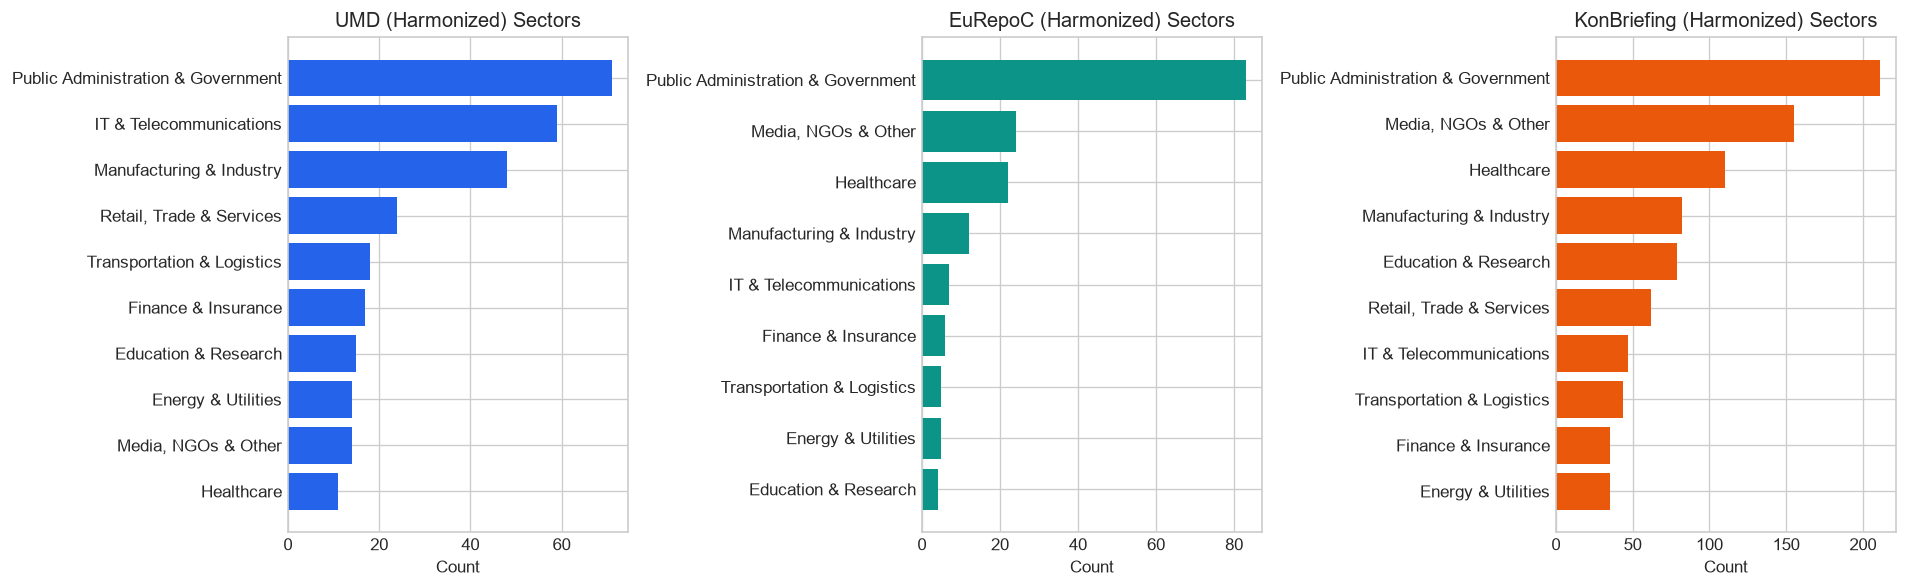

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, (name, df, col) in enumerate([
    ("UMD (Harmonized)", umd_clean, "#2563eb"),
    ("EuRepoC (Harmonized)", eur_clean, "#0d9488"),
    ("KonBriefing (Harmonized)", kb_clean, "#ea580c"),
]):
    counts = df["sector"].value_counts()
    axes[i].barh(counts.index, counts.values, color=col)
    axes[i].invert_yaxis()
    axes[i].set_title(f"{name} Sectors")
    axes[i].set_xlabel("Count")

plt.tight_layout()
plt.show()



**Validation Results:**
- **Zero unmapped garbage labels**: Every record cleanly maps into our 10 defined sectors!
- **Scientific Insight**: Notice how the three sources complement one another:
  - **KonBriefing** captures a vast amount of **Public Administration** (`240+` municipal and county targets) and **Healthcare** (`90+` hospitals and clinics).
  - **UMD** and **EuRepoC** add corporate targets like **Manufacturing & Industry** and **IT & Telecommunications**.

---

## 6. Detecting Overlaps & Deduplicating Across Trackers

When a prominent German attack happens (e.g. *Rheinmetall*, *Südwestfalen-IT*, or *Continental*), multiple trackers record it. If we simply concatenate the tables, these attacks would be double-counted.

Let us test for duplicate events by searching for incidents targeting the same normalized organization within **`±14 days`**.


In [10]:
combined = pd.concat([umd_clean, eur_clean, kb_clean], ignore_index=True)
combined = combined[combined["date"].notna()].sort_values("date").reset_index(drop=True)

GENERIC_NAMES = {
    "unknown", "undetermined", "undisclosed", "public sector", "company",
    "town hall", "city administration", "german companies", "not available"
}

def normalize_name(name):
    s = fix_mojibake(name).lower()
    s = re.sub(r"\b(gmbh|ag|se|kg|mbh|co|inc|corp|ltd|e\.?v\.?)\b", " ", s)
    s = re.sub(r"[^a-z0-9äöüß ]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return "" if (len(s) < 4 or s in GENERIC_NAMES) else s

combined["norm_victim"] = combined["victim_name"].apply(normalize_name)

def is_duplicate(row_a, row_b):
    a, b = row_a["norm_victim"], row_b["norm_victim"]
    if not a or not b:
        return False
    if abs((row_a["date"] - row_b["date"]).days) > 14:
        return False
    if a == b:
        return True
    if min(len(a), len(b)) >= 6 and (a in b or b in a):
        return True
    return SequenceMatcher(None, a, b).ratio() >= 0.82

# Search and preview sample duplicate pairs before merging
duplicate_sample = []
for i in range(len(combined)):
    for j in range(i + 1, min(i + 40, len(combined))):
        if (combined.iloc[j]["date"] - combined.iloc[i]["date"]).days > 14:
            break
        if combined.iloc[i]["source"] != combined.iloc[j]["source"] and is_duplicate(combined.iloc[i], combined.iloc[j]):
            duplicate_sample.append({
                "Date A": combined.iloc[i]["date"].strftime("%Y-%m-%d"),
                "Source A": combined.iloc[i]["source"],
                "Victim A": combined.iloc[i]["victim_name"],
                "Date B": combined.iloc[j]["date"].strftime("%Y-%m-%d"),
                "Source B": combined.iloc[j]["source"],
                "Victim B": combined.iloc[j]["victim_name"],
            })
            if len(duplicate_sample) >= 6:
                break
    if len(duplicate_sample) >= 6:
        break

print("Sample of overlapping incidents detected across different trackers:")
display(pd.DataFrame(duplicate_sample))



Sample of overlapping incidents detected across different trackers:


,Date A,Source A,Victim A,Date B,Source B,Victim B
0,2016-11-27,EuRepoC,Telekom,2016-11-29,UMD,Deutsche Telekom
1,2021-07-01,KonBriefing,Spread Group,2021-07-12,UMD,Spread Group
2,2021-10-23,UMD,Eberspacher Group,2021-10-25,KonBriefing,EberspAcher
3,2021-11-01,UMD,Medatixx,2021-11-01,KonBriefing,medatixx GmbH & Co. KG
4,2021-11-08,UMD,MediaMarkt,2021-11-08,KonBriefing,MediaMarktSaturn
5,2021-11-10,UMD,Kisters AG,2021-11-11,KonBriefing,KISTERS AG


### 6.1 Executing Deduplication and Generating `germany_large_incidents.csv`
When two records match across trackers:
- We combine their `source` tags (e.g. `"UMD + KonBriefing"`).
- We merge categorical fields using `pick_known` (preferring specific labels over `"Unknown"`).
- **Enriched fusion**:
  - `has_disruption` and `has_data_theft`: Logical OR (if any source confirmed it, flag is True).
  - `requires_user_interaction` and `zero_day_indicator`: Logical OR.
  - `severity_intensity_score`: Maximum score reported across sources.
  - `economic_impact_eur`: Retain confirmed monetary damage figures.


In [11]:
def pick_known(val_a, val_b):
    invalid = {"", "Unknown", "Undetermined", "Germany", "Unknown / Undetermined", "None"}
    if str(val_a) not in invalid and pd.notna(val_a):
        return val_a
    return val_b if (str(val_b) not in invalid and pd.notna(val_b)) else val_a

merged_records = []
used = [False] * len(combined)

for i in range(len(combined)):
    if used[i]:
        continue
    base = combined.iloc[i].to_dict()
    sources = [base["source"]]
    used[i] = True

    for j in range(i + 1, len(combined)):
        if (combined.iloc[j]["date"] - base["date"]).days > 14:
            break
        if used[j]:
            continue
        cand = combined.iloc[j]
        if is_duplicate(base, cand):
            used[j] = True
            if cand["source"] not in sources:
                sources.append(cand["source"])
            # Merge categorical labels
            for col in ["sector", "attack_type", "actor_type", "actor_name", "initiator_country",
                        "motive", "location_detail", "functional_impact", "data_breach_scope", "initial_access_vector"]:
                base[col] = pick_known(base[col], cand[col])
            # Merge enriched booleans & numerical metrics
            base["has_disruption"] = bool(base["has_disruption"] or cand["has_disruption"])
            base["has_data_theft"] = bool(base["has_data_theft"] or cand["has_data_theft"])
            base["requires_user_interaction"] = bool(base["requires_user_interaction"] or cand["requires_user_interaction"])
            base["zero_day_indicator"] = bool(base["zero_day_indicator"] or cand["zero_day_indicator"])
            base["severity_intensity_score"] = max(base["severity_intensity_score"], cand["severity_intensity_score"])
            if pd.notna(cand["economic_impact_eur"]):
                base["economic_impact_eur"] = cand["economic_impact_eur"] if pd.isna(base["economic_impact_eur"]) else max(base["economic_impact_eur"], cand["economic_impact_eur"])
            if len(str(cand["description"])) > len(str(base["description"])):
                base["description"] = cand["description"]

    source_order = ["UMD", "EuRepoC", "KonBriefing"]
    sources_sorted = [s for s in source_order if s in sources]
    base["source"] = " + ".join(sources_sorted)
    base["num_sources"] = len(sources_sorted)
    merged_records.append(base)

large_incidents = pd.DataFrame(merged_records).sort_values("date").reset_index(drop=True)
large_incidents["incident_id"] = [f"DE_{idx + 1:04d}" for idx in range(len(large_incidents))]
large_incidents["year"] = large_incidents["date"].dt.year
large_incidents["month"] = large_incidents["date"].dt.month
large_incidents["date"] = large_incidents["date"].dt.strftime("%Y-%m-%d")

cols_order = [
    "incident_id", "date", "year", "month", "victim_name", "location_detail",
    "sector", "attack_type", "actor_type", "actor_name", "initiator_country",
    "motive", "has_disruption", "has_data_theft", "functional_impact",
    "data_breach_scope", "severity_intensity_score", "initial_access_vector",
    "requires_user_interaction", "zero_day_indicator", "economic_impact_eur",
    "source", "num_sources", "description"
]
large_incidents = large_incidents[cols_order]

out_incidents_path = BASE_DIR / "germany_large_incidents.csv"
large_incidents.to_csv(out_incidents_path, index=False, encoding="utf-8")

print(f"Total raw dated records:            {len(combined):,}")
print(f"Final deduplicated large incidents: {len(large_incidents):,}")
print(f"Overlapping duplicates resolved:    {len(combined) - len(large_incidents)}")
print(f"Saved Dataset 1 to: {out_incidents_path}")



Total raw dated records:            1,319
Final deduplicated large incidents: 1,209
Overlapping duplicates resolved:    110
Saved Dataset 1 to: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\germany_large_incidents.csv


### 6.2 Visualizing the Enriched Incidents Dataset (Consequence & Vector Breakdown)
Let us inspect the distribution of sources, sectors, and the newly enriched operational disruption and entry vector dimensions.


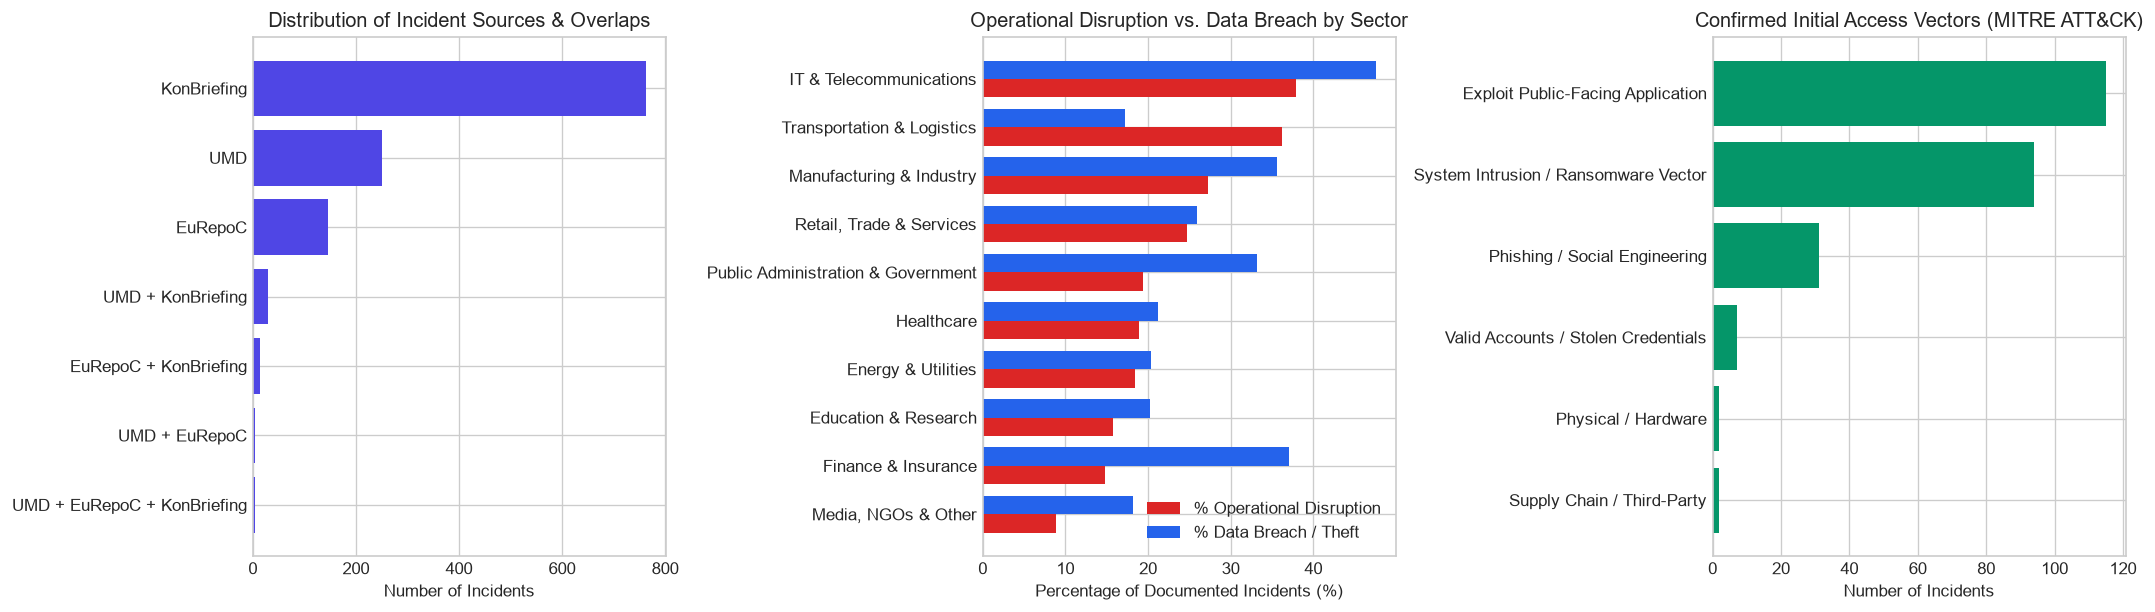

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1. Source overlap breakdown
src_dist = large_incidents["source"].value_counts()
axes[0].barh(src_dist.index, src_dist.values, color="#4f46e5")
axes[0].invert_yaxis()
axes[0].set_title("Distribution of Incident Sources & Overlaps")
axes[0].set_xlabel("Number of Incidents")

# 2. Operational Disruption vs Data Breach rate by Sector
sector_stats = large_incidents.groupby("sector").agg(
    disruption_rate=("has_disruption", "mean"),
    data_theft_rate=("has_data_theft", "mean"),
    count=("incident_id", "count")
).loc[lambda df: df["count"] >= 15].sort_values("disruption_rate")

y_pos = np.arange(len(sector_stats))
bar_h = 0.38
axes[1].barh(y_pos - bar_h/2, sector_stats["disruption_rate"] * 100, height=bar_h, label="% Operational Disruption", color="#dc2626")
axes[1].barh(y_pos + bar_h/2, sector_stats["data_theft_rate"] * 100, height=bar_h, label="% Data Breach / Theft", color="#2563eb")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(sector_stats.index)
axes[1].set_title("Operational Disruption vs. Data Breach by Sector")
axes[1].set_xlabel("Percentage of Documented Incidents (%)")
axes[1].legend(loc="lower right")

# 3. Known Initial Access Vectors (MITRE ATT&CK)
known_vecs = large_incidents[large_incidents["initial_access_vector"] != "Unknown / Undetermined"]["initial_access_vector"].value_counts()
axes[2].barh(known_vecs.index, known_vecs.values, color="#059669")
axes[2].invert_yaxis()
axes[2].set_title("Confirmed Initial Access Vectors (MITRE ATT&CK)")
axes[2].set_xlabel("Number of Incidents")

plt.tight_layout()
plt.show()



---

## 7. Compiling the Yearly Macro & Crime Overview (`germany_yearly_overview.csv`, 2014–2026)

### 7.1 Linking Documented Incidents to National Statistics
While `germany_large_incidents.csv` gives us detailed incident-level qualitative cases, **hundreds of thousands of smaller routine cybercrimes** are only captured in annual national police reports (BKA) and business surveys (Bitkom & Eurostat).

In this section, we compile **`germany_yearly_overview.csv`** (`2014–2026`, 1 row = 1 year) and integrate our newly enriched consequence metrics:
- **World Bank WDI**: National economic size and digital infrastructure growth.
- **BKA *Bundeslagebild Cybercrime***: Total police-recorded cybercrimes (*Inlandstaten* & *Auslandstaten*) and clearance rates.
- **Bitkom & Eurostat**: Total economic damages in € billions and representative enterprise security survey percentages.
- **Aggregated counts from Enriched Dataset 1**:
  - `documented_large_incidents` (total)
  - `documented_ransomware_incidents`
  - `documented_state_sponsored_incidents`
  - `documented_disruptive_incidents` (new)
  - `documented_data_theft_incidents` (new)
  - `avg_incident_intensity_score` (new)


In [13]:
# Load raw annual series
wb_yearly = pd.read_csv(RAW_DIR / "world_bank_germany.csv")
official_yearly = pd.read_csv(RAW_DIR / "bka_bitkom_eurostat_yearly.csv")

# Aggregate large incident counts and enriched consequence metrics by year (2014–2026)
inc_yearly = (
    large_incidents[(large_incidents["year"] >= 2014) & (large_incidents["year"] <= 2026)]
    .groupby("year")
    .agg(
        documented_large_incidents=("incident_id", "count"),
        documented_ransomware_incidents=("attack_type", lambda s: (s == "Ransomware").sum()),
        documented_state_sponsored_incidents=("actor_type", lambda s: (s == "State-Sponsored").sum()),
        documented_disruptive_incidents=("has_disruption", "sum"),
        documented_data_theft_incidents=("has_data_theft", "sum"),
        avg_incident_intensity_score=("severity_intensity_score", "mean"),
    )
    .reindex(range(2014, 2027), fill_value=0)
    .reset_index()
)

# Merge everything on year
yearly_overview = (
    wb_yearly
    .merge(official_yearly, on="year", how="left")
    .merge(inc_yearly, on="year", how="left")
)

yearly_overview["bka_cybercrime_total_known"] = (
    yearly_overview["bka_cybercrime_domestic"].fillna(0)
    + yearly_overview["bka_cybercrime_from_abroad"].fillna(0)
)
yearly_overview.loc[
    yearly_overview["bka_cybercrime_domestic"].isna() & yearly_overview["bka_cybercrime_from_abroad"].isna(),
    "bka_cybercrime_total_known"
] = np.nan

out_yearly_path = BASE_DIR / "germany_yearly_overview.csv"
yearly_overview.to_csv(out_yearly_path, index=False, encoding="utf-8")

print(f"Saved Dataset 2 ({yearly_overview.shape[0]} years × {yearly_overview.shape[1]} columns) to: {out_yearly_path}")
display(yearly_overview)



Saved Dataset 2 (13 years × 25 columns) to: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\germany_yearly_overview.csv


,year,gdp_billion_usd,gdp_per_capita_usd,gdp_growth_pct,industry_share_gdp_pct,internet_users_pct,fixed_broadband_per_100,rd_spending_gdp_pct,secure_servers_per_million,bka_cybercrime_domestic,...,eurostat_firms_security_policy_pct,eurostat_firms_risk_assessment_pct,eurostat_firms_cyber_insurance_pct,documented_large_incidents,documented_ransomware_incidents,documented_state_sponsored_incidents,documented_disruptive_incidents,documented_data_theft_incidents,avg_incident_intensity_score,bka_cybercrime_total_known
0,2014,3964.87,48959.60,2.18,25.99,86.19,36.34,2.82,3352.8,49925.0,...,NaN,NaN,NaN,9,1,4,3,6,1.777778,49925.0
1,2015,3425.10,41929.75,1.66,25.87,87.59,37.41,2.88,4297.9,45793.0,...,NaN,NaN,NaN,12,0,3,5,7,1.250000,45793.0
2,2016,3536.79,42948.94,2.22,26.17,84.17,38.50,2.88,11625.0,82649.0,...,NaN,NaN,NaN,11,0,4,2,9,1.454545,82649.0
3,2017,3765.35,45553.93,2.80,25.98,84.39,39.99,2.99,34181.3,85960.0,...,NaN,NaN,NaN,19,3,14,5,14,2.210526,85960.0
4,2018,4055.43,48916.17,1.14,25.85,87.04,40.97,3.05,56406.6,87106.0,...,NaN,NaN,NaN,17,0,9,1,15,1.352941,87106.0
5,2019,3959.89,47656.20,0.98,25.54,88.13,42.12,3.11,77970.0,100514.0,...,37.26,33.55,20.37,24,1,11,4,20,1.083333,100514.0
6,2020,3941.40,47394.87,-4.13,25.24,89.81,43.30,3.09,97517.6,108474.0,...,NaN,NaN,NaN,34,11,3,22,21,1.647059,108474.0
7,2021,4355.25,52349.25,3.91,25.16,91.43,44.06,3.08,113297.6,146363.0,...,NaN,NaN,NaN,133,17,5,24,18,1.917293,247363.0
8,2022,4201.02,50506.52,1.81,25.56,91.63,44.62,3.07,126884.1,136865.0,...,35.56,37.30,32.28,234,18,13,61,61,2.123932,246365.0
9,2023,4562.21,54776.77,-0.87,26.80,92.48,45.38,3.15,139972.8,134407.0,...,NaN,NaN,NaN,301,36,21,51,73,2.149502,274692.0


### 7.2 Visualizing Macro Trends, Crime Dynamics, and Incident Consequences (2014–2026)
With all indicators aligned on `year`, we can visually inspect Germany's macroeconomic exposure, police cybercrime volume, and the evolution of disruptive vs. data-theft incidents.


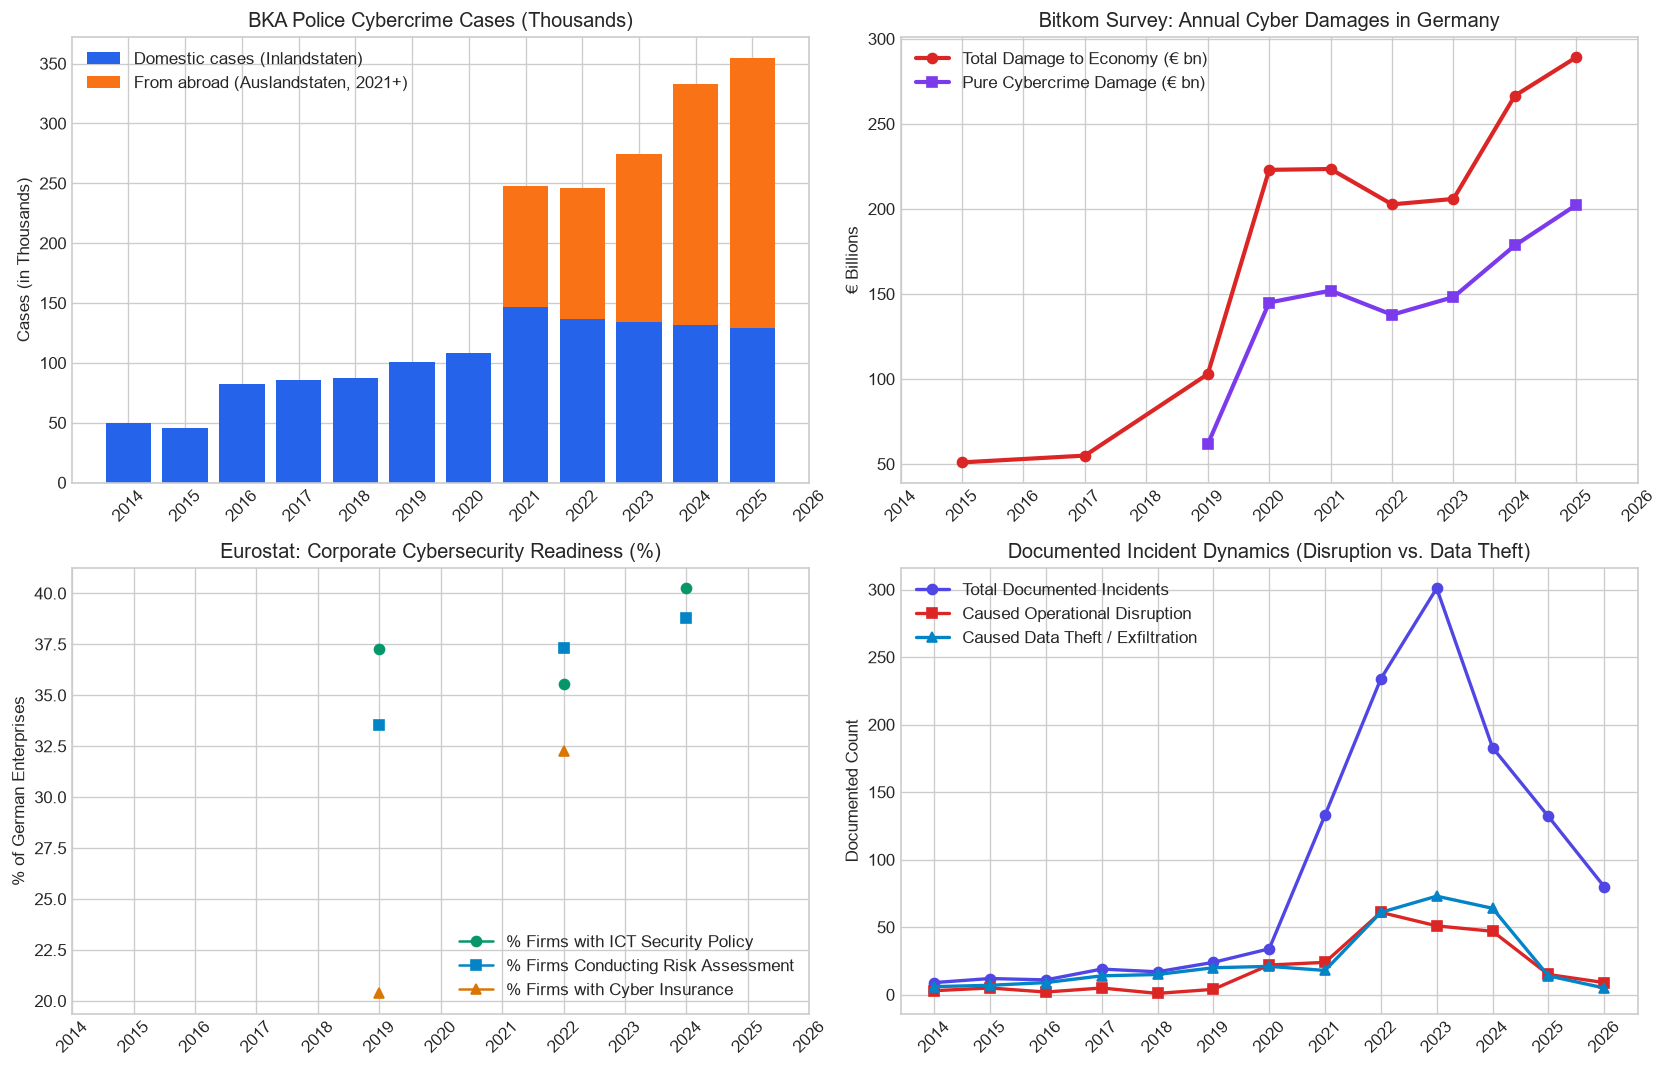

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
x = yearly_overview["year"]

# 1. BKA Police Cybercrime (Domestic vs From Abroad)
dom = yearly_overview["bka_cybercrime_domestic"] / 1000
abr = yearly_overview["bka_cybercrime_from_abroad"].fillna(0) / 1000
axes[0, 0].bar(x, dom, color="#2563eb", label="Domestic cases (Inlandstaten)")
axes[0, 0].bar(x, abr, bottom=dom, color="#f97316", label="From abroad (Auslandstaten, 2021+)")
axes[0, 0].set_title("BKA Police Cybercrime Cases (Thousands)")
axes[0, 0].set_ylabel("Cases (in Thousands)")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels([str(y) for y in x], rotation=45)
axes[0, 0].legend()

# 2. Bitkom Economic Damage (€ Billions)
bitkom_cyber = yearly_overview["bitkom_cyber_damage_eur_bn"]
bitkom_total = yearly_overview["bitkom_total_damage_eur_bn"]
axes[0, 1].plot(x[bitkom_total.notna()], bitkom_total.dropna(), marker="o", color="#dc2626", linewidth=2.5, label="Total Damage to Economy (€ bn)")
axes[0, 1].plot(x[bitkom_cyber.notna()], bitkom_cyber.dropna(), marker="s", color="#7c3aed", linewidth=2.5, label="Pure Cybercrime Damage (€ bn)")
axes[0, 1].set_title("Bitkom Survey: Annual Cyber Damages in Germany")
axes[0, 1].set_ylabel("€ Billions")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels([str(y) for y in x], rotation=45)
axes[0, 1].legend()

# 3. Eurostat Enterprise Survey Trends
axes[1, 0].plot(x, yearly_overview["eurostat_firms_security_policy_pct"], marker="o", color="#059669", label="% Firms with ICT Security Policy")
axes[1, 0].plot(x, yearly_overview["eurostat_firms_risk_assessment_pct"], marker="s", color="#0284c7", label="% Firms Conducting Risk Assessment")
axes[1, 0].plot(x, yearly_overview["eurostat_firms_cyber_insurance_pct"], marker="^", color="#d97706", label="% Firms with Cyber Insurance")
axes[1, 0].set_title("Eurostat: Corporate Cybersecurity Readiness (%)")
axes[1, 0].set_ylabel("% of German Enterprises")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([str(y) for y in x], rotation=45)
axes[1, 0].legend()

# 4. Enriched Documented Incidents: Disruption vs Data Theft Dynamics
axes[1, 1].plot(x, yearly_overview["documented_large_incidents"], marker="o", color="#4f46e5", linewidth=2, label="Total Documented Incidents")
axes[1, 1].plot(x, yearly_overview["documented_disruptive_incidents"], marker="s", color="#dc2626", linewidth=2, label="Caused Operational Disruption")
axes[1, 1].plot(x, yearly_overview["documented_data_theft_incidents"], marker="^", color="#0284c7", linewidth=2, label="Caused Data Theft / Exfiltration")
axes[1, 1].set_title("Documented Incident Dynamics (Disruption vs. Data Theft)")
axes[1, 1].set_ylabel("Documented Count")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels([str(y) for y in x], rotation=45)
axes[1, 1].legend()

plt.tight_layout()
plt.show()



---

## 8. Summary of Analysis-Ready Datasets & Decision Model Roadmap

The enriched data preparation workflow has produced two clean, analysis-ready CSV files in `./germany/`:

1. **`germany_large_incidents.csv` (Enriched)**
   - **Rows**: 1,209 individual documented cyber incidents in Germany (`2006–2026`).
   - **Columns (23)**: `incident_id`, `date`, `year`, `month`, `victim_name`, `location_detail`, `sector`, `attack_type`, `actor_type`, `actor_name`, `initiator_country`, `motive`, `has_disruption`, `has_data_theft`, `functional_impact`, `data_breach_scope`, `severity_intensity_score`, `initial_access_vector`, `requires_user_interaction`, `zero_day_indicator`, `economic_impact_eur`, `source`, `num_sources`, `description`.
   - **Analytical Value**: Unlocks cross-tabulation of consequences by sector, empirical testing of double-extortion ransomware prevalence, and modeling initial entry vulnerabilities (human factor vs. perimeter systems).

2. **`germany_yearly_overview.csv` (Enriched)**
   - **Rows**: 13 years (`2014` through `2026`).
   - **Columns (25)**: Macro/digital indicators (World Bank), police mass cybercrime volume and solve rates (BKA), corporate damage totals (Bitkom), enterprise security preparedness base-rates (Eurostat), and aggregated annual counts of large, disruptive, data-theft, and ransomware attacks.

### 8.1 Direct Link to the Decision Analysis Model (Modeli in Odločitveni Sistemi)
These enriched datasets provide the quantitative criteria needed for our course's core deliverable:
* **Alternative Countermeasures**:
  - $A_1$: Targeted Employee Phishing Defense & Awareness Training.
  - $A_2$: Public-Facing Server Patch Management & Zero-Day Hardening.
  - $A_3$: Critical Operational Resiliency & Redundant Backups (Anti-Disruption).
  - $A_4$: Data Loss Prevention & Zero-Trust Architecture (Anti-Exfiltration).
* **Evaluation Criteria**:
  - Likelihood $P$ (incident volume by sector).
  - Operational Disruption Impact $I_{	ext{ops}}$ (`has_disruption`, `functional_impact`).
  - Confidentiality Impact $I_{	ext{data}}$ (`has_data_theft`, `data_breach_scope`).
  - Vulnerability to Human Error $V_{	ext{human}}$ (`requires_user_interaction`).
  - Existing Preparedness Baseline (Eurostat policy adoption).

With this enriched empirical foundation, we are ready to proceed to formal statistical testing (regression, hypothesis tests) and the Multi-Criteria Decision Model (MCDA / DEXi / AHP).
